In [1]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)


Writing lab07_lib.py


In [2]:
%%writefile lab07_demo.py
# ЛР 7. Демонстрационный вариант 1: набор «диск», фактор «размер латентного вектора 8 → 2».
import numpy as np
import lab07_lib as L

N = 1
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

# Серия из пяти seed: метрики режимов A и B
result = L.variant_summary(N)
for name, a, s, b, d, q, sig in result["rows"]:
    print(f"{name:8s} A={a:8.3f} s={s:6.3f} B={b:8.3f} d={d:+8.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

# Тривиальный эталон: средняя картинка обучающей выборки, одинаковая для всех входов
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(L.psnr_images(mean_image, Xte), 3))

# Диагностика: PSNR в зависимости от размера латентного вектора (seed 101, 102, 103)
for d in (1, 2, 3, 4, 8):
    vals = [L.run(L.KINDS[c], dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

# Лист сравнения comparison.png: оригиналы, реконструкции режима A и режима B (seed 101, первые 8 тестовых сцен)
from PIL import Image
rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet


Writing lab07_demo.py


In [3]:
"""ЛР07, вариант 13: первичные измерения и диагностика; запуск в новой папке."""
from pathlib import Path
from datetime import datetime, timezone, timedelta
import contextlib
import hashlib
import io
import json
import platform
import shutil
import subprocess
import sys
import numpy as np
import torch
from PIL import Image
import lab07_lib as L

OUT = Path('artifacts')
OUT.mkdir(exist_ok=False)
now = lambda: datetime.now(timezone(timedelta(hours=3))).isoformat()
def save(name, data):
    (OUT/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
plan = dict(recorded_at=now(), variant=13, kind='disc_noise', factor='latent_8_to_2', seeds=list(range(101,106)),
    hypothesis='Уменьшение d с 8 до 2 снизит PSNR более чем на 1 дБ; изменение разрыва останется в пределах 0,1 дБ. Число параметров уменьшится, существенное ускорение не ожидается. Непредсказуемый шум датчика не будет воспроизводиться в обоих режимах.',
    tolerances=dict(psnr_absolute=1.0, gap_absolute=0.1, seconds_relative=0.2),
    rules='Граница допуска нейтральна; PSNR выше — лучше; разрыв и время ниже — лучше. Параметры оцениваются точно без 2s и без допуска; экономия полезна при приемлемом PSNR.',
    diagnostic=dict(d=[1,2,3,4,8], seeds=[101,102,103], reuse='Основные A/B повторно используются при d=8/2.'),
    demonstration='Сначала исходный lab07_demo.py выполняется целиком для N=1; далее отдельный опыт N=13.')
save('expectations_before_run.json',plan)
print('ПЛАН ДО ЗАПУСКА',json.dumps(plan,ensure_ascii=False,indent=2),flush=True)
assert torch.cuda.is_available(), 'Нужна CUDA/T4'
env=dict(recorded_at=now(),python=sys.version, platform=platform.platform(), torch=torch.__version__,numpy=np.__version__,pillow=__import__('PIL').__version__,cuda=torch.version.cuda,gpu=torch.cuda.get_device_name(0),
 nvidia_smi=subprocess.check_output(['nvidia-smi'],text=True),pip_list=subprocess.check_output([sys.executable,'-m','pip','list','--format=json'],text=True),
 library_sha256=sha('lab07_lib.py'),demo_sha256=sha('lab07_demo.py'))
save('environment.json',env)
class Tee(io.StringIO):
    def write(self,s):
        sys.__stdout__.write(s);sys.__stdout__.flush();return super().write(s)
log=Tee()
with contextlib.redirect_stdout(log):
    print('НАЧАЛО',now())
    print('ДЕМОНСТРАЦИЯ N=1 — исходный код без изменений',flush=True)
    exec(compile(Path('lab07_demo.py').read_text(), 'lab07_demo.py','exec'),{'__name__':'__main__'})
    shutil.move('comparison.png',OUT/'comparison_demo01.png')
    print('ОСНОВНОЙ ОПЫТ N=13',now(),flush=True)
    a,b=L.settings(L.FACTORS[0]);print('A',a,'B',b)
    assert [k for k in a if a[k]!=b[k]]==['d']
    records=[];arrays={};diagnostic=[];original_run=L.run
    def tracked(kind,cfg,seed):
        started=now();metrics,model=original_run(kind,cfg,seed)
        if seed in range(101,106):
            mode='A' if cfg['d']==8 else 'B'
            Xtr,Xte,_,_=L.dataset(kind)
            r=L.reconstruct(model,Xte);rtr=L.reconstruct(model,Xtr[:1024])
            arrays[f'{mode}_{seed}_test_mse']=((r-Xte)**2).flatten(1).mean(1).cpu().numpy()
            arrays[f'{mode}_{seed}_train_mse']=((rtr-Xtr[:1024])**2).flatten(1).mean(1).cpu().numpy()
            records.append(dict(mode=mode,seed=seed,started_at=started,finished_at=now(),metrics=metrics))
            if seed==101:
                arrays[f'{mode}_reconstruction']=r[:8].cpu().numpy()
                torch.save(model.state_dict(), OUT/f'model_{mode}_seed101.pt')
            print(mode,seed,metrics,flush=True)
        return metrics,model
    L.run=tracked
    result=L.variant_summary(13)
    L.run=original_run
    # JSON имеет null вместо нечислового отношения при s=0.
    result['rows']=[list(row[:5])+[row[5] if np.isfinite(row[5]) else None,row[6]] for row in result['rows']]
    save('summary.json',result);save('raw_metrics.json',records)
    Xtr,Xte,Ftr,Fte=L.dataset('disc_noise')
    mean=Xtr.mean(0,keepdim=True).expand_as(Xte)
    baseline=L.psnr_images(mean,Xte)
    arrays['mean_test_mse']=((mean-Xte)**2).flatten(1).mean(1).cpu().numpy()
    arrays['original']=Xte[:8].cpu().numpy()
    arrays['factors_test_first8']=Fte[:8].cpu().numpy()
    # Чистые сцены тех же факторов нужны только для дополнительной проверки шума.
    clean=np.stack([L.render('disc',f) for f in Fte[:8].cpu().numpy()])
    arrays['clean_first8']=clean
    save('baseline.json',dict(psnr=baseline, target='noisy test images',n_test=1024))
    for d in (1,2,3,4,8):
        vals=[]
        for seed in (101,102,103):
            if d in (2,8):
                mode='A' if d==8 else 'B'
                v=next(x['metrics']['psnr'] for x in records if x['seed']==seed and x['mode']==mode)
                origin='main series'
            else:
                v=original_run('disc_noise',dict(L.BASE,d=d),seed)[0]['psnr'];origin='new training'
            vals.append(v)
        diagnostic.append(dict(d=d,seeds=[101,102,103],psnr=vals,mean=float(np.mean(vals)),sd=float(np.std(vals,ddof=1)),origin=origin))
        print('ДИАГНОСТИКА',diagnostic[-1],flush=True)
    save('diagnostic.json',diagnostic)
    np.savez_compressed(OUT/'measurements.npz',**arrays)
    grid=np.concatenate([np.concatenate(list(arr.transpose(0,2,3,1)),axis=1) for arr in [arrays['original'],arrays['A_reconstruction'],arrays['B_reconstruction']]],axis=0)
    Image.fromarray((grid*255).round().astype('uint8')).resize((1024,384),Image.Resampling.NEAREST).save(OUT/'comparison.png')
    noise_check={}
    for mode in ['original','A_reconstruction','B_reconstruction']:
        residual=arrays[mode]-clean
        # Фон за пределами любого диска: первые четыре строки.
        noise_check[mode]=dict(background_residual_std=float(residual[:,:,:4,:].std()),clean_psnr_first8=float(np.mean(-10*np.log10(np.maximum((residual**2).mean(axis=(1,2,3)),1e-10)))))
    save('noise_check.json',noise_check)
    repeat=[]
    for mode,cfg in [('A',a),('B',b)]:
        m,_=original_run('disc_noise',cfg,101)
        first=next(x['metrics']['psnr'] for x in records if x['mode']==mode and x['seed']==101)
        repeat.append(dict(mode=mode,seed=101,psnr_initial=first,psnr_repeat=m['psnr'],difference=m['psnr']-first))
    save('repeat_check.json',repeat)
    save('passport.json',dict(variant=13,kind='disc_noise',configs=dict(A=a,B=b),data_seed=7,n_train=4096,n_test=1024,train_eval=1024,epochs=20,batch=128,optimizer='Adam',lr=0.002,updates=640,seeds=list(range(101,106)),dtype='float32',target='noisy images, sigma=0.05; no extra training/eval corruption',baseline_psnr=baseline,plan_time=plan['recorded_at'],main_started_at=records[0]['started_at'],finished_at=now(),source_hashes={n:sha(n) for n in ['lab07_lib.py','lab07_demo.py']},limitations='CUDA convolution algorithms are not forced deterministic; runtime varies. Diagnostic reuses main-series d=2/8 for seeds 101..103.'))
    print('ИТОГ',result,'ЭТАЛОН',baseline,'ПОВТОР',repeat,now(),flush=True)
(OUT/'run.log').write_text(log.getvalue(),encoding='utf-8')
print('ГОТОВО: artifacts/passport.json')


ПЛАН ДО ЗАПУСКА {
  "recorded_at": "2026-10-18T23:40:41.025725+03:00",
  "variant": 13,
  "kind": "disc_noise",
  "factor": "latent_8_to_2",
  "seeds": [
    101,
    102,
    103,
    104,
    105
  ],
  "hypothesis": "Уменьшение d с 8 до 2 снизит PSNR более чем на 1 дБ; изменение разрыва останется в пределах 0,1 дБ. Число параметров уменьшится, существенное ускорение не ожидается. Непредсказуемый шум датчика не будет воспроизводиться в обоих режимах.",
  "tolerances": {
    "psnr_absolute": 1.0,
    "gap_absolute": 0.1,
    "seconds_relative": 0.2
  },
  "rules": "Граница допуска нейтральна; PSNR выше — лучше; разрыв и время ниже — лучше. Параметры оцениваются точно без 2s и без допуска; экономия полезна при приемлемом PSNR.",
  "diagnostic": {
    "d": [
      1,
      2,
      3,
      4,
      8
    ],
    "seeds": [
      101,
      102,
      103
    ],
    "reuse": "Основные A/B повторно используются при d=8/2."
  },
  "demonstration": "Сначала исходный lab07_demo.py выполняетс

НАЧАЛО 2026-10-18T23:40:42.646119+03:00
ДЕМОНСТРАЦИЯ N=1 — исходный код без изменений
A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'conv', 'd': 2, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
psnr     A=  26.069 s= 0.674 B=  23.199 d=  -2.870 |d|/s=   4.26 2s=да
gap      A=   0.038 s= 0.015 B=   0.096 d=  +0.058 |d|/s=   3.95 2s=да
params   A= 101.035 s= 0.000 B=  88.741 d= -12.294 |d|/s=    inf 2s=да
seconds  A=   1.809 s= 0.155 B=   1.752 d=  -0.056 |d|/s=   0.36 2s=нет
эталон «средняя картинка», PSNR на тесте: 17.171
d=1: PSNR = 20.69 дБ (по seed: 20.70, 20.82, 20.57)
d=2: PSNR = 23.16 дБ (по seed: 23.33, 23.42, 22.74)
d=3: PSNR = 25.27 дБ (по seed: 24.75, 24.79, 26.26)
d=4: PSNR = 26.15 дБ (по seed: 26.70, 25.66, 26.08)
d=8: PSNR = 25.80 дБ (по seed: 25.70, 26.66, 25.03)
ОСНОВНОЙ ОПЫТ N=13 2026-10-18T23:41:40.034431+03:00
A {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0

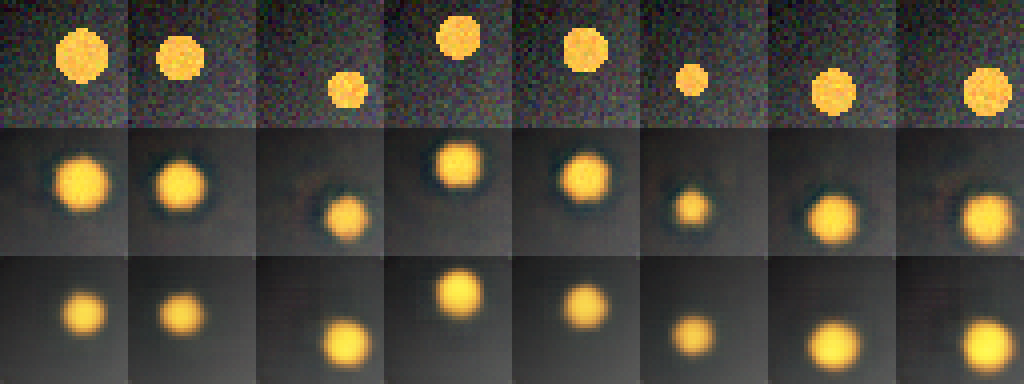

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import shutil
from google.colab import files
from IPython.display import display, Image
assert (OUT/'passport.json').exists()
print((OUT/'run.log').read_text())
display(Image(filename=str(OUT/'comparison.png')))
shutil.make_archive('lab07_13_artifacts', 'zip', 'artifacts')
files.download('lab07_13_artifacts.zip')